# Week 5 — Neural Policy Gradient Methods

This self-contained experiment implements the Week 5 assignment in PyTorch. It compares **REINFORCE**, **REINFORCE with a learned value baseline**, and **one-step Actor–Critic** on five Gymnasium environments. Each environment gets a learning-curve chart with all three methods.

The methods follow Sutton & Barto, *Reinforcement Learning: An Introduction*, 2nd ed., Chapter 13. Weeks 3–4 supply the Monte Carlo return and function-approximation foundation. PPO, the 1707.06347 paper, the ICLR “37 details” article, and CleanRL were consulted as implementation context; PPO is not one of the three assigned algorithms and is not used here.

**Run top to bottom in local Jupyter Notebook or JupyterLab.** The install cell makes the notebook self-contained. It uses only CPU PyTorch and Gymnasium; all selected environments have discrete actions. Training and chart cells run all 15 method/environment combinations across multiple random seeds.

## Assignment checklist

- Five Gymnasium environments: CliffWalking, Taxi, CartPole, MountainCar, and Acrobot.
- PyTorch neural network policies for all environments. Discrete observations use one-hot vectors; continuous observations use normalized coordinates.
- Three algorithms are implemented directly from the Sutton–Barto updates.
- Each environment has one chart comparing smoothed episodic returns for all algorithms, aggregated across seeds, plus a final performance summary.

The return plots are an empirical analogue of the learning curves in Figure 13.2. The shaded band is ±1 standard error across seeds; the line is a trailing moving average of episodic return.

## 1. Environment and runtime setup

The environment list is deliberately varied: two discrete-state tasks and three continuous-state control tasks. CliffWalking provides a compact discrete-state control task with informative negative rewards; the other environment settings use Gymnasium defaults.

In [1]:
%pip -q install "gymnasium>=1.0,<2" "numpy>=1.24" "matplotlib>=3.7" "torch>=2.2"

Note: you may need to restart the kernel to use updated packages.


In [2]:
from __future__ import annotations

import math
import random
import time
from dataclasses import dataclass
from typing import Any

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.distributions import Categorical

%matplotlib inline

DEVICE = torch.device("cpu")
torch.set_num_threads(1)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.22, "font.size": 10})

ENV_IDS = ["CliffWalking-v1", "Taxi-v4", "CartPole-v1", "MountainCar-v0", "Acrobot-v1"]
ENV_KWARGS: dict[str, dict[str, Any]] = {}
# Training budgets can be changed here before running the experiment.
EPISODES_BY_ENV = {env_id: 500 for env_id in ENV_IDS}
SEEDS = [7, 17, 27]  # independent replications for mean and standard-error curves
GAMMA = 0.99
HIDDEN_SIZES = (32, 32)

print("PyTorch:", torch.__version__)
print("Gymnasium:", gym.__version__)
print("Environments:", ", ".join(ENV_IDS))

PyTorch: 2.15.0
Gymnasium: 1.4.0
Environments: CliffWalking-v1, Taxi-v4, CartPole-v1, MountainCar-v0, Acrobot-v1


## 2. Policy-gradient updates

For a differentiable stochastic policy, the policy-gradient theorem gives an update proportional to

\[
\nabla_\theta J(\theta) = \mathbb{E}_{\pi_\theta}\!\left[\nabla_\theta\log\pi_\theta(A_t\mid S_t)\,q_{\pi_\theta}(S_t,A_t)\right].
\]

The three methods differ in the learning signal multiplying the log-policy gradient:

1. **REINFORCE:** use the sampled return \(G_t=\sum_{k=t}^{T-1}\gamma^{k-t}R_{k+1}\). For the episodic start-state objective with discounting, the update also weights time \(t\) by \(\gamma^t\).
2. **REINFORCE with baseline:** replace \(G_t\) with \(G_t-\hat v(S_t;w)\). A state-only baseline leaves the expected policy gradient unchanged. The critic is fit by a Monte Carlo squared-error update toward \(G_t\).
3. **One-step Actor–Critic:** use the TD error \(\delta_t=R_{t+1}+\gamma\hat v(S_{t+1};w)-\hat v(S_t;w)\), with zero next-state value at termination. Update the actor with \(\gamma^t\delta_t\nabla\log\pi\) and the critic by semi-gradient TD(0).

All actor steps use stochastic gradient **ascent** (implemented as minimizing the negative objective). The baseline critic is updated with a stop-gradient target. Actor–Critic computes each TD target before either parameter update, so gradients do not flow through the target. This is an on-policy episodic comparison; no replay buffer, advantage normalization, clipping, or PPO update is used.

## 3. Observation encoding and neural networks

Discrete observations are encoded as one-hot vectors, which also lets the same MLP handle the 500 Taxi states. Continuous observations are scaled by task-specific ranges and clipped to keep network inputs well-conditioned. The actor outputs one logit per discrete action. The critic is a separate state-value network.

In [3]:
OBS_SCALE = {
    "CartPole-v1": np.array([4.8, 5.0, 0.42, 5.0], dtype=np.float32),
    "MountainCar-v0": np.array([1.8, 0.14], dtype=np.float32),
    # Acrobot has four sine/cosine coordinates and two angular velocities.
    "Acrobot-v1": np.array([1.0, 1.0, 1.0, 1.0, 4.0 * math.pi, 9.0 * math.pi], dtype=np.float32),
}


MAX_EPISODE_STEPS = 200  # also bounds environments without a built-in TimeLimit


def make_env(env_id: str):
    # Use one common finite horizon; Gymnasium reports the cap as truncation.
    return gym.make(env_id, max_episode_steps=MAX_EPISODE_STEPS,
                    **ENV_KWARGS.get(env_id, {}))


def encoded_obs(env_id: str, observation: Any, observation_space: gym.Space) -> np.ndarray:
    if isinstance(observation_space, gym.spaces.Discrete):
        result = np.zeros(observation_space.n, dtype=np.float32)
        result[int(observation)] = 1.0
        return result
    if isinstance(observation_space, gym.spaces.Box):
        values = np.asarray(observation, dtype=np.float32).reshape(-1)
        scale = OBS_SCALE.get(env_id)
        if scale is None or scale.shape != values.shape:
            low = np.asarray(observation_space.low, dtype=np.float32).reshape(-1)
            high = np.asarray(observation_space.high, dtype=np.float32).reshape(-1)
            scale = np.maximum(np.maximum(np.abs(low), np.abs(high)), 1.0)
            scale[~np.isfinite(scale)] = 1.0
        return np.clip(values / scale, -5.0, 5.0).astype(np.float32)
    raise TypeError(f"Unsupported observation space for {env_id}: {observation_space}")


class MLP(nn.Module):
    def __init__(self, input_dim: int, output_dim: int):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_dim, HIDDEN_SIZES[0]), nn.Tanh(),
            nn.Linear(HIDDEN_SIZES[0], HIDDEN_SIZES[1]), nn.Tanh(),
            nn.Linear(HIDDEN_SIZES[1], output_dim),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.layers(x)


def state_tensor(state: np.ndarray) -> torch.Tensor:
    return torch.as_tensor(state, dtype=torch.float32, device=DEVICE).unsqueeze(0)


def sample_action(actor: nn.Module, state: np.ndarray) -> tuple[int, torch.Tensor]:
    distribution = Categorical(logits=actor(state_tensor(state)))
    action = distribution.sample()
    return int(action.item()), distribution.log_prob(action).squeeze(0)


@dataclass
class Episode:
    states: list[np.ndarray]
    actions: list[int]
    rewards: list[float]


def collect_episode(env: gym.Env, actor: nn.Module, env_id: str, seed: int | None = None) -> Episode:
    observation, _ = env.reset(seed=seed)
    states: list[np.ndarray] = []
    actions: list[int] = []
    rewards: list[float] = []
    terminated = truncated = False
    while not (terminated or truncated):
        state = encoded_obs(env_id, observation, env.observation_space)
        action, _ = sample_action(actor, state)
        next_observation, reward, terminated, truncated, _ = env.step(action)
        states.append(state)
        actions.append(action)
        rewards.append(float(reward))
        observation = next_observation
    return Episode(states, actions, rewards)


def discounted_returns(rewards: list[float], gamma: float) -> torch.Tensor:
    result = np.zeros(len(rewards), dtype=np.float32)
    running = 0.0
    for t in reversed(range(len(rewards))):
        running = rewards[t] + gamma * running
        result[t] = running
    return torch.as_tensor(result, dtype=torch.float32, device=DEVICE)


def make_models(env: gym.Env) -> tuple[MLP, MLP, int]:
    probe, _ = env.reset(seed=0)
    input_dim = len(encoded_obs(env.spec.id, probe, env.observation_space))
    actor = MLP(input_dim, int(env.action_space.n)).to(DEVICE)
    critic = MLP(input_dim, 1).to(DEVICE)
    return actor, critic, input_dim

## 4. The three learning algorithms

The step sizes below are kept common across environments for a readable comparison. The same environment/seed pair is used for each method, while each method has its own initialization and on-policy trajectory. Environment rewards are left unchanged.

In [4]:
ACTOR_LR = 1.0e-3
CRITIC_LR = 1.0e-3


def values_for(critic: nn.Module, states: list[np.ndarray]) -> torch.Tensor:
    batch = torch.as_tensor(np.stack(states), dtype=torch.float32, device=DEVICE)
    return critic(batch).squeeze(-1)


def train_reinforce(env_id: str, episodes: int, seed: int) -> np.ndarray:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    env = make_env(env_id)
    actor, _, _ = make_models(env)
    optimizer = torch.optim.SGD(actor.parameters(), lr=ACTOR_LR)
    returns_history = np.zeros(episodes, dtype=np.float32)
    try:
        for episode_index in range(episodes):
            episode = collect_episode(env, actor, env_id, seed if episode_index == 0 else None)
            returns = discounted_returns(episode.rewards, GAMMA)
            # Sutton–Barto applies one stochastic ascent step for each time step.
            for t, (state, action) in enumerate(zip(episode.states, episode.actions)):
                log_prob = Categorical(logits=actor(state_tensor(state))).log_prob(
                    torch.tensor(action, device=DEVICE)
                )
                loss = -(GAMMA ** t) * returns[t] * log_prob
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            returns_history[episode_index] = sum(episode.rewards)
    finally:
        env.close()
    return returns_history


def train_reinforce_baseline(env_id: str, episodes: int, seed: int) -> np.ndarray:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    env = make_env(env_id)
    actor, critic, _ = make_models(env)
    actor_optimizer = torch.optim.SGD(actor.parameters(), lr=ACTOR_LR)
    critic_optimizer = torch.optim.SGD(critic.parameters(), lr=CRITIC_LR)
    returns_history = np.zeros(episodes, dtype=np.float32)
    try:
        for episode_index in range(episodes):
            episode = collect_episode(env, actor, env_id, seed if episode_index == 0 else None)
            targets = discounted_returns(episode.rewards, GAMMA)
            # Update actor and state baseline once per visited time step.
            for t, (state, action) in enumerate(zip(episode.states, episode.actions)):
                state_input = state_tensor(state)
                log_prob = Categorical(logits=actor(state_input)).log_prob(
                    torch.tensor(action, device=DEVICE)
                )
                baseline = critic(state_input).squeeze().detach()
                actor_loss = -(GAMMA ** t) * (targets[t] - baseline) * log_prob
                actor_optimizer.zero_grad()
                actor_loss.backward()
                actor_optimizer.step()
                # Monte Carlo semi-gradient: v(S_t) moves toward G_t.
                prediction = critic(state_input).squeeze()
                critic_loss = 0.5 * (prediction - targets[t]).pow(2)
                critic_optimizer.zero_grad()
                critic_loss.backward()
                critic_optimizer.step()
            returns_history[episode_index] = sum(episode.rewards)
    finally:
        env.close()
    return returns_history


def train_actor_critic(env_id: str, episodes: int, seed: int) -> np.ndarray:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    env = make_env(env_id)
    actor, critic, _ = make_models(env)
    actor_optimizer = torch.optim.SGD(actor.parameters(), lr=ACTOR_LR)
    critic_optimizer = torch.optim.SGD(critic.parameters(), lr=CRITIC_LR)
    returns_history = np.zeros(episodes, dtype=np.float32)
    try:
        for episode_index in range(episodes):
            observation, _ = env.reset(seed=seed if episode_index == 0 else None)
            episode_return = 0.0
            discount_weight = 1.0
            terminated = truncated = False
            while not (terminated or truncated):
                state = encoded_obs(env_id, observation, env.observation_space)
                action, log_prob = sample_action(actor, state)
                next_observation, reward, terminated, truncated, _ = env.step(action)
                episode_return += float(reward)
                state_value = critic(state_tensor(state)).squeeze()
                if terminated:
                    next_value = torch.zeros((), dtype=torch.float32, device=DEVICE)
                else:
                    # A Gymnasium time-limit truncation is not an MDP terminal;
                    # bootstrap through it. True task termination has value zero.
                    next_state = encoded_obs(env_id, next_observation, env.observation_space)
                    with torch.no_grad():
                        next_value = critic(state_tensor(next_state)).squeeze()
                # One-step TD error; the target is fixed for both updates.
                delta = (torch.tensor(float(reward), dtype=torch.float32, device=DEVICE)
                         + GAMMA * next_value - state_value)
                actor_loss = -(discount_weight * delta.detach() * log_prob)
                actor_optimizer.zero_grad()
                actor_loss.backward()
                actor_optimizer.step()
                critic_loss = 0.5 * delta.pow(2)
                critic_optimizer.zero_grad()
                critic_loss.backward()
                critic_optimizer.step()
                observation = next_observation
                discount_weight *= GAMMA
            returns_history[episode_index] = episode_return
    finally:
        env.close()
    return returns_history

ALGORITHMS = {
    "REINFORCE": train_reinforce,
    "REINFORCE + baseline": train_reinforce_baseline,
    "Actor–Critic": train_actor_critic,
}
print("Implemented:", ", ".join(ALGORITHMS))

Implemented: REINFORCE, REINFORCE + baseline, Actor–Critic


## 5. Run all environments and seeds

This cell trains every method on every environment. It stores raw undiscounted episode returns for the requested performance plots, while the learning updates use discounted returns. The configured budget is 500 episodes per seed and environment. Increase it in `EPISODES_BY_ENV` for a longer learning study.

In [5]:
results: dict[str, dict[str, list[np.ndarray]]] = {
    env_id: {name: [] for name in ALGORITHMS} for env_id in ENV_IDS
}
started_at = time.perf_counter()
for env_id in ENV_IDS:
    budget = EPISODES_BY_ENV[env_id]
    print(f"\n{env_id}: {budget} episodes × {len(SEEDS)} seeds")
    for algorithm_name, train_function in ALGORITHMS.items():
        for seed in SEEDS:
            curve = train_function(env_id, budget, seed)
            results[env_id][algorithm_name].append(curve)
            window = max(1, budget // 5)
            print(f"  {algorithm_name:22s} seed={seed:>2}: "
                  f"first-{window} mean={curve[:window].mean():8.2f}, "
                  f"last-{window} mean={curve[-window:].mean():8.2f}")
print(f"\nTraining wall time: {(time.perf_counter() - started_at) / 60:.1f} minutes")


CliffWalking-v1: 500 episodes × 3 seeds


  REINFORCE              seed= 7: first-100 mean= -216.83, last-100 mean= -200.00


  REINFORCE              seed=17: first-100 mean= -228.71, last-100 mean= -200.00


  REINFORCE              seed=27: first-100 mean= -215.84, last-100 mean= -200.00


  REINFORCE + baseline   seed= 7: first-100 mean= -216.83, last-100 mean= -200.00


  REINFORCE + baseline   seed=17: first-100 mean= -228.71, last-100 mean= -200.00


... (36 outputs left out)

  REINFORCE + baseline   seed=27: first-100 mean= -200.00, last-100 mean= -200.00


  Actor–Critic           seed= 7: first-100 mean= -200.00, last-100 mean= -200.00


  Actor–Critic           seed=17: first-100 mean= -200.00, last-100 mean= -200.00


  Actor–Critic           seed=27: first-100 mean= -200.00, last-100 mean= -200.00

Training wall time: 16.0 minutes


## 6. One learning-curve chart per environment

Each line is the seed-mean trailing average return. The shaded area shows ±1 standard error across independent seeds. We plot raw reward scale for each task, so compare algorithms within a chart; reward scales differ between environments.

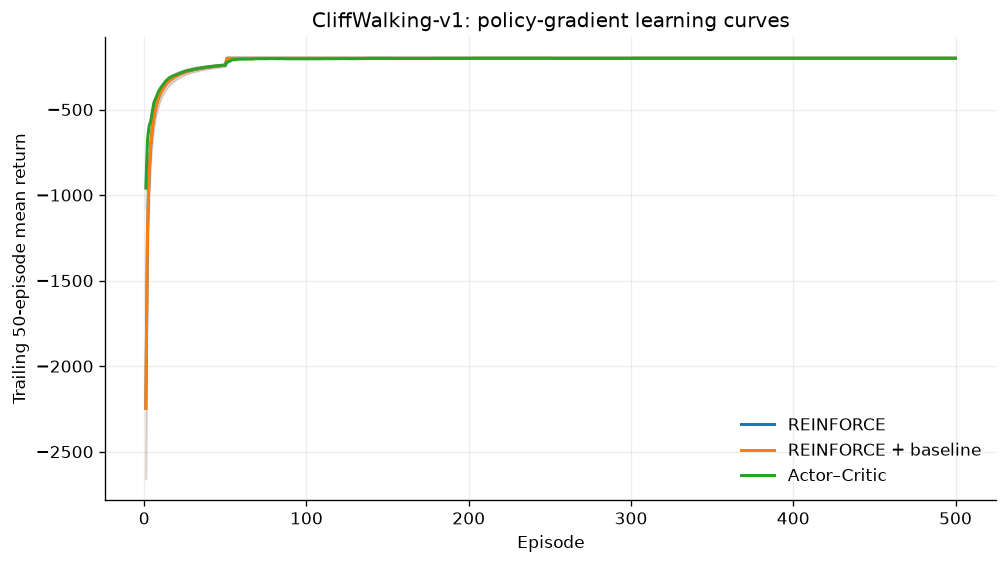

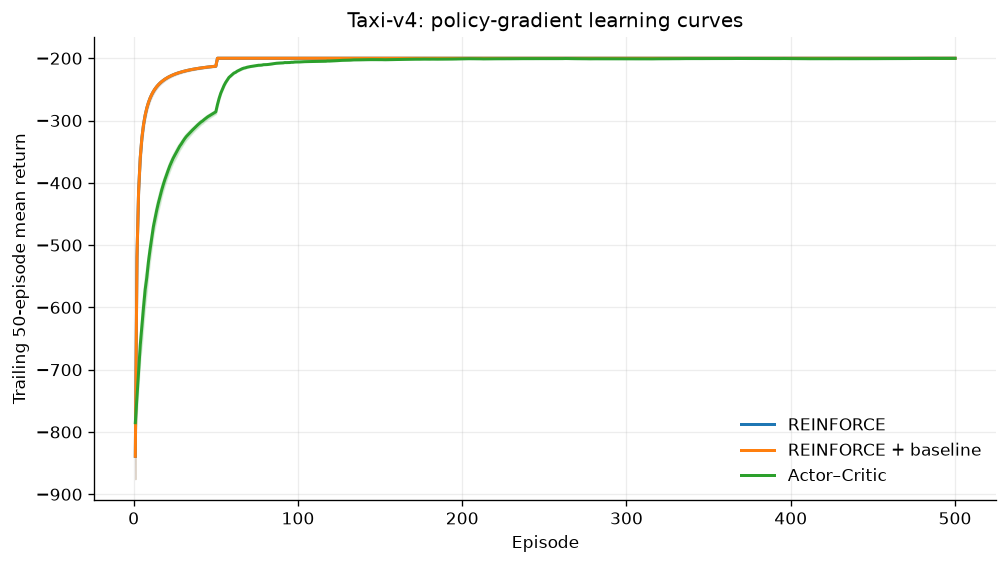

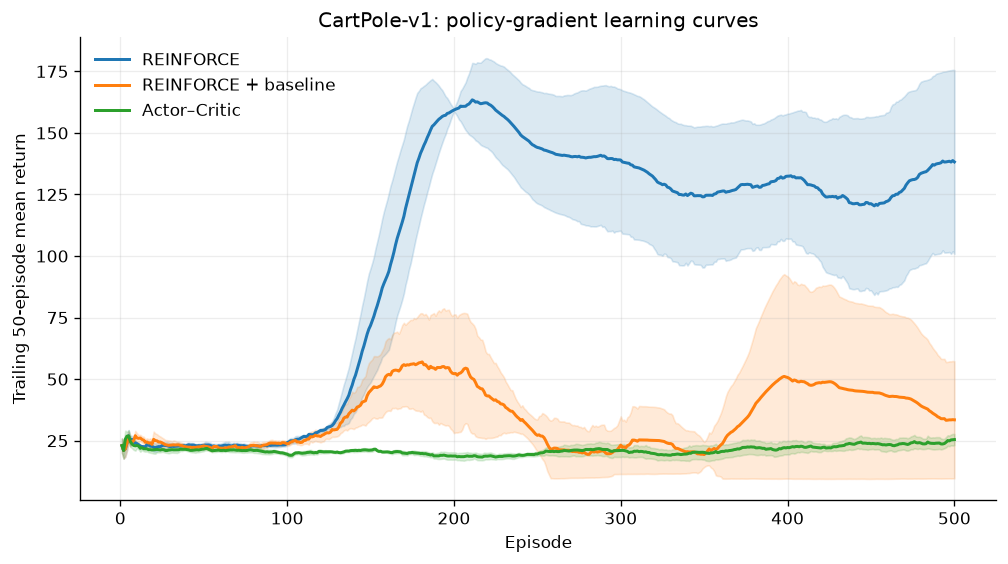

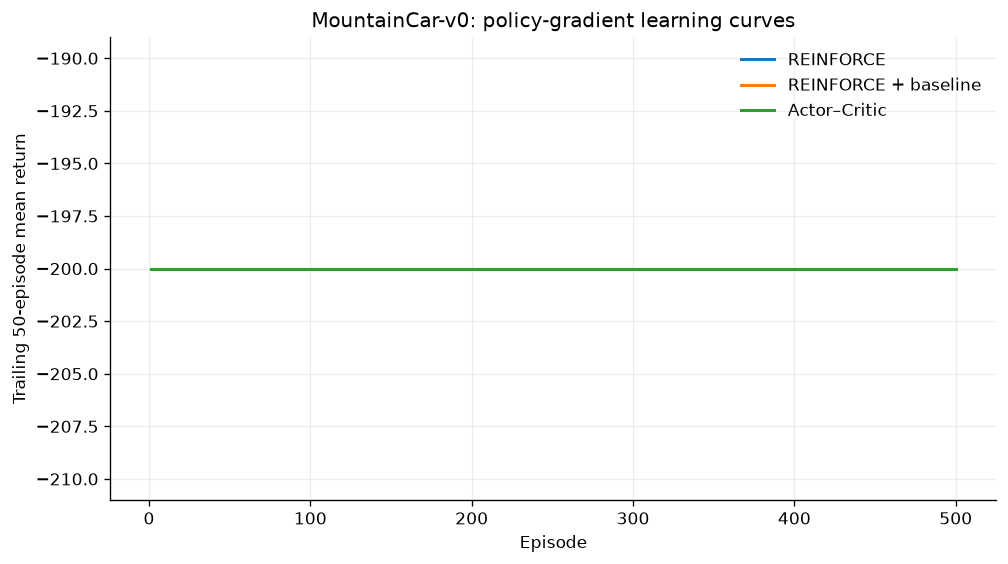

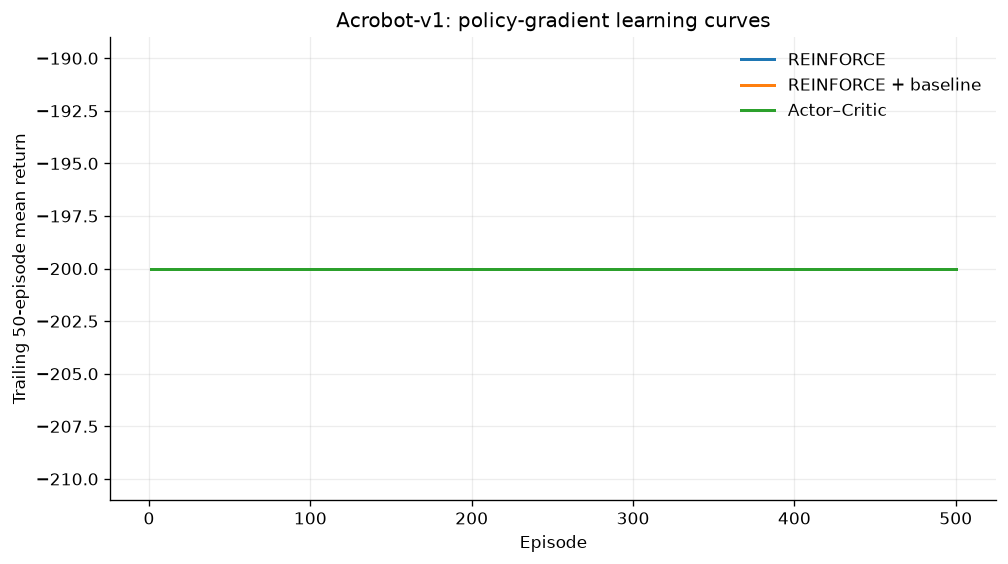

In [6]:
COLORS = {
    "REINFORCE": "#1f77b4",
    "REINFORCE + baseline": "#ff7f0e",
    "Actor–Critic": "#2ca02c",
}
SMOOTHING_WINDOW = 50


def moving_average(values: np.ndarray, window: int) -> np.ndarray:
    if window <= 1:
        return values.copy()
    cumulative = np.concatenate(([0.0], np.cumsum(values, dtype=np.float64)))
    ends = np.arange(1, len(values) + 1)
    starts = np.maximum(0, ends - window)
    return (cumulative[ends] - cumulative[starts]) / (ends - starts)


for env_id in ENV_IDS:
    fig, ax = plt.subplots(figsize=(8.5, 4.8))
    for algorithm_name, seed_curves in results[env_id].items():
        curves = np.stack([moving_average(curve, SMOOTHING_WINDOW) for curve in seed_curves])
        mean = curves.mean(axis=0)
        stderr = curves.std(axis=0, ddof=1) / math.sqrt(curves.shape[0]) if curves.shape[0] > 1 else np.zeros_like(mean)
        x = np.arange(1, len(mean) + 1)
        color = COLORS[algorithm_name]
        ax.plot(x, mean, color=color, label=algorithm_name, linewidth=1.8)
        ax.fill_between(x, mean - stderr, mean + stderr, color=color, alpha=0.16)
    ax.set_title(f"{env_id}: policy-gradient learning curves")
    ax.set_xlabel("Episode")
    ax.set_ylabel(f"Trailing {SMOOTHING_WINDOW}-episode mean return")
    ax.legend(frameon=False)
    fig.tight_layout()
    plt.show()

## 7. Final performance summary

The table reports the mean and standard deviation across seeds for the average return over each run's final 100 episodes. The learning curves remain the primary comparison: this compact statistic does not measure sample efficiency or uncertainty over environment randomness within a seed.

In [7]:
summary_rows = []
for env_id in ENV_IDS:
    for algorithm_name, seed_curves in results[env_id].items():
        final_means = np.array([curve[-min(100, len(curve)):].mean() for curve in seed_curves])
        summary_rows.append((env_id, algorithm_name, float(final_means.mean()),
                             float(final_means.std(ddof=1)) if len(final_means) > 1 else 0.0))

print(f"{'Environment':18s} {'Algorithm':23s} {'Final 100-ep return (mean ± SD)'}")
print("-" * 78)
for env_id, algorithm_name, mean, std in summary_rows:
    print(f"{env_id:18s} {algorithm_name:23s} {mean:9.2f} ± {std:.2f}")

Environment        Algorithm               Final 100-ep return (mean ± SD)
------------------------------------------------------------------------------
CliffWalking-v1    REINFORCE                 -200.00 ± 0.00
CliffWalking-v1    REINFORCE + baseline      -200.00 ± 0.00
CliffWalking-v1    Actor–Critic              -200.00 ± 0.00
Taxi-v4            REINFORCE                 -200.00 ± 0.00
Taxi-v4            REINFORCE + baseline      -200.00 ± 0.00
Taxi-v4            Actor–Critic              -200.45 ± 0.24
CartPole-v1        REINFORCE                  129.75 ± 61.75
CartPole-v1        REINFORCE + baseline        39.06 ± 51.03
CartPole-v1        Actor–Critic                24.62 ± 3.84
MountainCar-v0     REINFORCE                 -200.00 ± 0.00
MountainCar-v0     REINFORCE + baseline      -200.00 ± 0.00
MountainCar-v0     Actor–Critic              -200.00 ± 0.00
Acrobot-v1         REINFORCE                 -200.00 ± 0.00
Acrobot-v1         REINFORCE + baseline      -200.00 ± 0.00
Acro

## 8. Interpretation and reproducibility notes

Use each chart to describe the learning trend, variance across seeds, and whether the baseline methods improve learning speed or stability on that environment. Do not infer a universal winner from five tasks: reward sparsity, episode horizon, dynamics, and observation representation differ.

- **REINFORCE** updates only after an episode and uses complete Monte Carlo returns.
- **REINFORCE with baseline** has the same actor target minus a state-only value estimate; its critic uses complete returns.
- **Actor–Critic** updates during the episode with a one-step bootstrap target. True termination has zero continuation value; a 200-step Gymnasium time-limit truncation bootstraps from the critic's next-state estimate.
- All networks use two 32-unit Tanh hidden layers and plain SGD. Each environment is capped at 200 steps per episode for a bounded comparison; Gymnasium marks this as truncation. The policy is categorical and supports all five discrete-action tasks.
- Seeds control initialization, action sampling, and the first environment reset. Gymnasium is reset without a repeated seed afterward so environment randomness advances across episodes.

The implementation intentionally stays with Chapter 13 policy-gradient methods. PPO's clipped surrogate objective, multiple epochs over rollout batches, value clipping, and other engineering choices discussed by Schulman et al., the ICLR implementation-details article, and CleanRL would change the algorithm being compared. Those readings are useful context for later policy optimization work, not prerequisites for reproducing these three assignment methods.

### References

- Sutton, R. S. & Barto, A. G. *Reinforcement Learning: An Introduction*, 2nd ed., Chapter 13 (Policy Gradient Methods).
- François-Lavet et al. *Foundations of Deep Reinforcement Learning*, Chapter 7 (provided as `H173704.pdf`).
- Schulman et al. “Proximal Policy Optimization Algorithms,” arXiv:1707.06347v2.
- Huang et al. “The 37 Implementation Details of Proximal Policy Optimization,” ICLR Blog Track.
- CleanRL, “Proximal Policy Gradient (PPO)” implementation notes.
- Course notebooks: Week 3 Monte Carlo/TD learning; Week 4 function-approximation prediction and control.

## 8. Results from this local run

The notebook ran on CPU with PyTorch 2.15.0 and Gymnasium 1.4.0. It completed 500 episodes per environment and algorithm for each of three seeds, with a 200-step episode cap. The five charts and summary table above are embedded outputs from this run (about 16 minutes).

- **CartPole:** REINFORCE had the highest final 100-episode mean return (129.75, seed SD 61.75). REINFORCE with baseline reached 39.06 (SD 51.03), while Actor–Critic reached 24.62 (SD 3.84). The large seed variation means this short experiment does not establish that vanilla REINFORCE is generally better.
- **CliffWalking and Taxi:** returns moved upward from early episodes but approached roughly −200, which is the 200-step timeout scale. These policies did not reliably reach the goal within the run budget.
- **MountainCar and Acrobot:** all three methods stayed near −200, the return from using the full capped episode. The 500-episode runs were not enough for these policies to solve either task.

These are finite-budget results, not convergence claims. The charts show why policy-gradient performance depends on exploration, reward structure, step sizes, and episode budget. The shaded bands are standard errors across only three seeds, so treat them as descriptive rather than strong statistical evidence. For a deeper study, increase the episode budgets for MountainCar and Acrobot and compare several step sizes while keeping the same evaluation protocol.